Installation of required Python packages

In [1]:
import numpy as np
from qutip import *
import qutip as qt
import matplotlib.pyplot as plt
from scipy import integrate

Defining the paramaters. The parameters will be defined in electron volts.

In [2]:
Delta = -30 * 10**(-3)   # The paper takes this value as a variable. This is the energy difference with the donor singlet excited state and charge tranfer states.
v0 = 75 * 10**(-3)  # coupling with direct spin tranfer
vSOCp = 25 * 10**(-3) # spin orbit coupling corresponding to right circular polarisation
vSOCn = -25 * 10**(-3) # spin orbit coupling corresponding to left circular polarisation

fD = 0.4 
fCT = 0.4   # The Bath coupling terms, much smaller than other coupling terms.

The following analysis omits the vibronic coupling part. We define the atomic states in the next cell.

In [3]:
nob = 6    # Number of basis states

Dsp  = basis(nob,0)  # The Singlet excited donor state with RCP
CTsp = basis(nob,1)  # The singlet charge transfer state with RCP
CTtp = basis(nob,2)  # The triplet charge transfer state with RCP
Dsn  = basis(nob,3) # The Singlet excited donor state with LCP
CTsn = basis(nob,4)  # The singlet charge transfer state with LCP
CTtn = basis(nob,5)  # The triplet charge transfer state with RCP



The following step defines the Hamiltonian.

In [4]:
H = Delta*( CTsp*CTsp.dag() + CTtp*CTtp.dag()  ) + v0*( Dsp*CTsp.dag() + CTsp*Dsp.dag() ) + vSOCp*( Dsp*CTtp.dag() + CTtp*Dsp.dag() ) + Delta*( CTsn*CTsn.dag() + CTtn*CTtn.dag()  ) + v0*( Dsn*CTsn.dag() + CTsn*Dsn.dag() ) + vSOCn*( Dsn*CTtn.dag() + CTtn*Dsn.dag() )

Populations of different states. Propagator takes h-cap as 1 and we have used Hamiltonian in electron volts. Hence the natural unit of time from propagatir operator is 0.65821 femtoseconds.

In [5]:
t = np.linspace(0,200 / 0.658212,1000) # 200 femtoseconds
P1 = np.zeros(1000)
P2 = np.zeros(1000)
P3 = np.zeros(1000)

for i in range(0,1000):
    Ut = qt.propagator(H,t[i])
    stt = Ut * Dsp
    P1[i] = abs((Dsp.dag()*stt))**2
    P2[i] = abs((CTsp.dag()*stt))**2
    P3[i] = abs((CTtp.dag()*stt))**2

Plotting the populations

[]

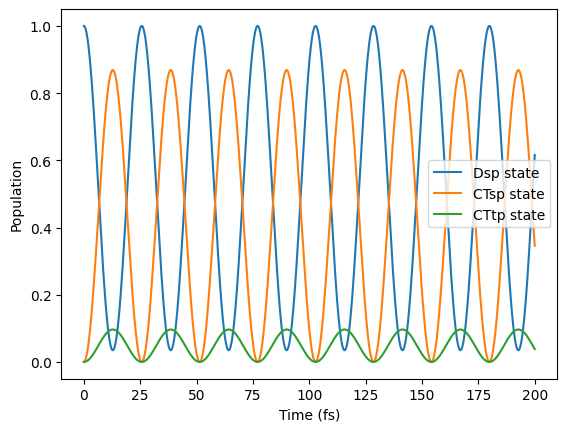

In [6]:
plt.figure()
t_sec = t * 0.658212
plt.plot(t_sec,P1,label ="Dsp state")
plt.plot(t_sec,P2,label ="CTsp state")
plt.plot(t_sec,P3,label ="CTtp state")
plt.legend()
plt.xlabel("Time (fs)")
plt.ylabel("Population")
plt.plot()

Spin Polarization operator is defined below.

In [7]:
Pz = CTtp*CTsp.dag() + CTsp*CTtp.dag() + CTtn*CTsn.dag() + CTsn*CTtn.dag()

The variation of Spin polarization over time.

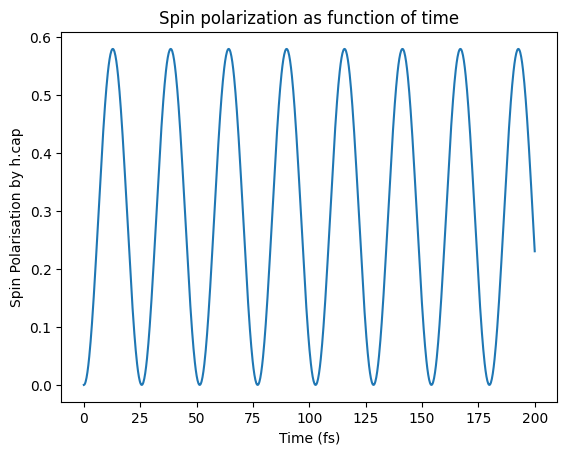

In [8]:
t = np.linspace(0,200 / 0.658212,1000) # 200 femtoseconds
Pzt = np.zeros(1000)

for i in range(0,1000):
    Ut = qt.propagator(H,t[i])
    stt = Ut * Dsp
    Pzt[i] = np.real(stt.dag()*Pz*stt)

plt.figure()
t_sec = t * 0.658212
plt.plot(t_sec,Pzt)
plt.title("Spin polarization as function of time")
plt.xlabel("Time (fs)")
plt.ylabel("Spin Polarisation by h.cap")
plt.show()


To find the mean polarisation as a function of energy difference we will be integrating the Spin polarisation over time and divide over the toatl time. So we are repeating the procedure for every value of Delta(energy difference)

In [9]:
Mean_Pzp = np.zeros(200)
Mean_Pzn = np.zeros(200)
delta = np.linspace(-60,60,200) * 10**(-3)
tav = np.linspace(0,10000 / 0.658212,10000)
tav_sec = tav*0.658212

def Hamiltonian(delta):
    H =  delta*( CTsp*CTsp.dag() + CTtp*CTtp.dag()  ) + v0*( Dsp*CTsp.dag() + CTsp*Dsp.dag() ) + vSOCp*( Dsp*CTtp.dag() + CTtp*Dsp.dag() ) + delta*( CTsn*CTsn.dag() + CTtn*CTtn.dag()  ) + v0*( Dsn*CTsn.dag() + CTsn*Dsn.dag() ) + vSOCn*( Dsn*CTtn.dag() + CTtn*Dsn.dag() )
    return H

for i in range(200):
    H = Hamiltonian(delta[i])
    
    result_p = qt.sesolve(H, Dsp, tav, e_ops=[Pz])
    result_n = qt.sesolve(H, Dsn, tav, e_ops=[Pz])
    
    Pzpt = result_p.expect[0]
    Pznt = result_n.expect[0]
    
    Mean_Pzp[i] = integrate.simpson(Pzpt, tav_sec) / max(tav_sec)
    Mean_Pzn[i] = integrate.simpson(Pznt, tav_sec) / max(tav_sec)

C:\Users\haric\AppData\Local\Temp\ipykernel_30876\1798244366.py:20: DeprecationWarning: You are passing x=[0.00000000e+00 1.00010001e+00 2.00020002e+00 ... 9.99799980e+03
 9.99899990e+03 1.00000000e+04] as a positional argument. Please change your invocation to use keyword arguments. From SciPy 1.14, passing these as positional arguments will result in an error.
  Mean_Pzp[i] = integrate.simpson(Pzpt, tav_sec) / max(tav_sec)
C:\Users\haric\AppData\Local\Temp\ipykernel_30876\1798244366.py:21: DeprecationWarning: You are passing x=[0.00000000e+00 1.00010001e+00 2.00020002e+00 ... 9.99799980e+03
 9.99899990e+03 1.00000000e+04] as a positional argument. Please change your invocation to use keyword arguments. From SciPy 1.14, passing these as positional arguments will result in an error.
  Mean_Pzn[i] = integrate.simpson(Pznt, tav_sec) / max(tav_sec)


Plotting the dependence of Mean polarization on energy difference.

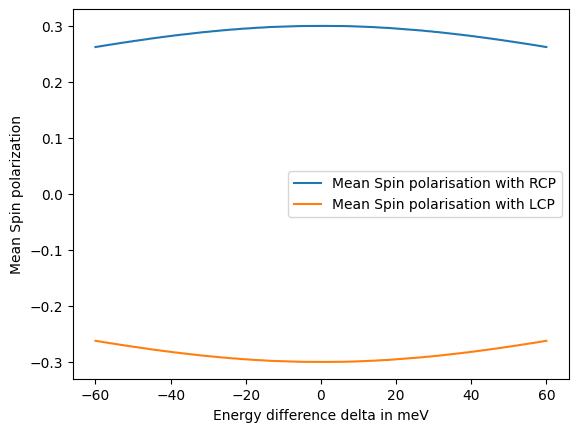

In [10]:
plt.figure()
plt.plot(delta*1000,Mean_Pzp,label = "Mean Spin polarisation with RCP")
plt.plot(delta*1000,Mean_Pzn,label = "Mean Spin polarisation with LCP")
plt.legend()
plt.xlabel("Energy difference delta in meV")
plt.ylabel("Mean Spin polarization")
plt.show()

Including the Vibronic coupling through a Bath and Bloch-Redfield equations. First let us caluclate the Bloch tensor. The coupling operator is given by

In [11]:
Ve = fD*(Dsp*Dsn.dag() + Dsn*Dsp.dag()) + fCT*( CTsp*CTsn.dag() +  CTsn*CTsp.dag() + CTtp*CTtn.dag() + CTtn*CTtp.dag())

The following cell is the Spectral density function. We are using the Fourier transformation of the Drude Lorentz density function. We are dropping the imaginary part.

In [12]:
L = 0.2*10**(-3)                     # eV
wc = 30*10**(-3)                     # Cutoff frequency

def J(w):
    J = 2*L*w*wc/(w**2 + wc**2)
    return J

T  = 300                             # Temperature
kT = 8.617333e-5*T                   # eV

def spectrum(w):                 
    if abs(w) < 1e-10:               # If w is very small.
        return 4*np.pi*L*kT/wc
    n = 1/np.expm1(abs(w)/kT)
    return 2*np.pi*J(abs(w))*(n + (w > 0))

The following cell is the Bloch-Redfield tensor constructed with inbulit functions of QuTiP.

In [13]:
R, ekets = qt.bloch_redfield_tensor(H, [[Ve, spectrum]], sec_cutoff=-1)

The difference operator between the two enantimeric states is defined below.

In [14]:
Np = Dsp*Dsp.dag() + CTsp*CTsp.dag() + CTtp*CTtp.dag()
Nn = Dsn*Dsn.dag() + CTsn*CTsn.dag() + CTtn*CTtn.dag()
Del_N = Np - Nn

Running the simulation using Bloch field equation.

In [15]:
pi = Dsp*Dsp.dag()                                # Initial density function
t = np.linspace(0,2000 / 0.658212,8000)           # 2000 femto seconds

res = qt.brmesolve(H, pi, t,
                   a_ops=[(Ve, spectrum)],
                   e_ops=[Pz, Del_N],
                   sec_cutoff=-1,        
                   options={"atol": 1e-10, "rtol": 1e-8})                 # The command runs the simulation till 2000 fetoseconds and gives the expectation value.

Pz_t, DelN_t = res.expect[0], res.expect[1]

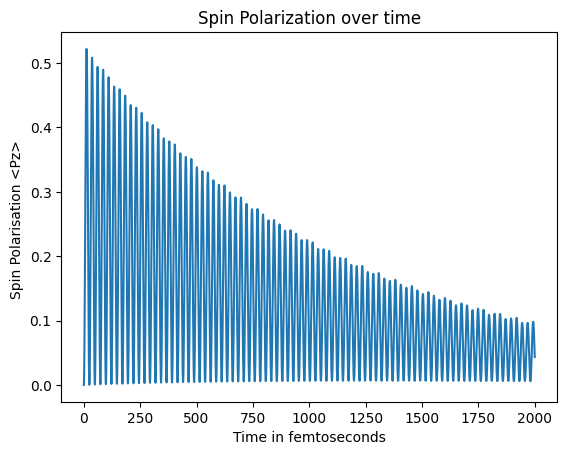

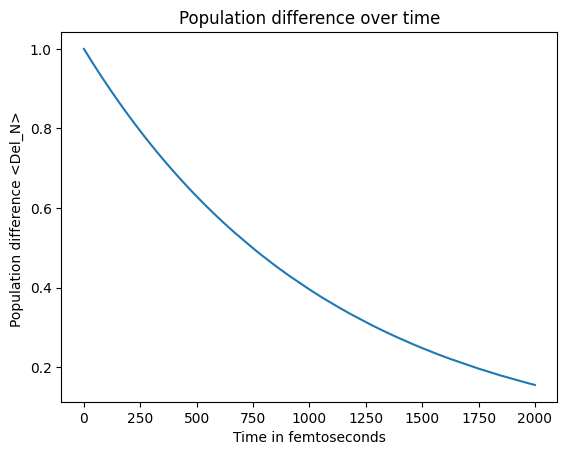

In [16]:
plt.figure()
plt.plot(t*0.658212,Pz_t)
plt.title("Spin Polarization over time")
plt.xlabel("Time in femtoseconds")
plt.ylabel("Spin Polarisation <Pz> ")
plt.show()

plt.figure()
plt.plot(t*0.658212,DelN_t)
plt.title("Population difference over time")
plt.xlabel("Time in femtoseconds")
plt.ylabel("Population difference <Del_N> ")
plt.show()

The following code finds the decay rate of the Population difference and Spin polarisation.

In [17]:
import numpy as np
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

tfs = t * 0.658212            

# --- Gamma_N: fit <Delta N>(t) ---
(GN,), _ = curve_fit(lambda x, g: np.exp(-g*x), tfs, DelN_t, p0=[1e-3])

# --- Gamma_P: fit <Pz>(t) ---
pk, _ = find_peaks(Pz_t)
(A, GP), _ = curve_fit(lambda x, A, g: A*np.exp(-g*x),
                       tfs[pk], Pz_t[pk], p0=[Pz_t[pk][0], 1e-3])

print(f"Gamma_N = {GN*1e3:.3f} ps^-1")
print(f"Gamma_P = {GP*1e3:.3f} ps^-1")
print(f"ratio Gamma_P/Gamma_N = {GP/GN:.3f}")

Gamma_N = 0.928 ps^-1
Gamma_P = 0.859 ps^-1
ratio Gamma_P/Gamma_N = 0.925


In the following cell, the Bloch-Redfield caluclation is repeated for different values of coupling in the System-Bath system. We will analyse the decay rate with effective coupling rate.

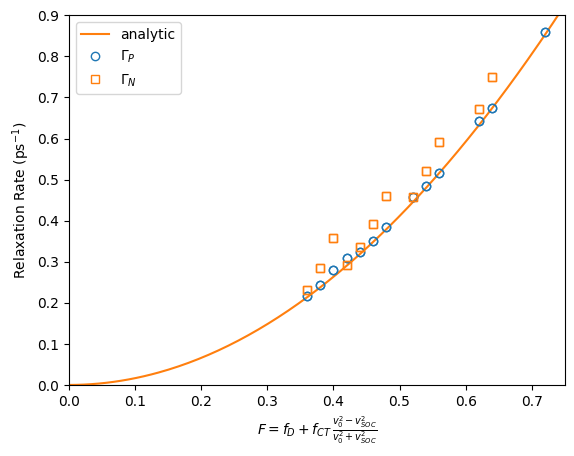

In [18]:
ratio = (v0**2 - vSOCp**2)/(v0**2 + vSOCp**2)
f = np.linspace(-0.4,0.4,9)
f1 = np.linspace(0.1,0.4,6)

Fs = []
G_N = []
G_P = []

for fD in f:
        #fCT = 0.4
    for fCT in f:
        F = fD + fCT*ratio           # Effective coupling
        if abs(F) < 0.35 :           # For proper calculation we need this limit. Or else the code crashes.
            continue
        Ve = fD*(Dsp*Dsn.dag() + Dsn*Dsp.dag()) + fCT*( CTsp*CTsn.dag() +  CTsn*CTsp.dag() + CTtp*CTtn.dag() + CTtn*CTtp.dag())
        res = qt.brmesolve(H, pi, t, a_ops=[(Ve, spectrum)], e_ops=[Pz, Del_N], sec_cutoff=-1,options={"atol": 1e-10, "rtol": 1e-8})
        Pz_t, dN_t = res.expect

        gN = curve_fit(lambda x, g: np.exp(-g*x), tfs, dN_t, p0=[1e-3])[0][0]
        pk, _ = find_peaks(Pz_t)
        gP = curve_fit(lambda x, A, g: A*np.exp(-g*x), tfs[pk], Pz_t[pk],
                       p0=[Pz_t[pk][0], 1e-3])[0][1]

        Fs.append(abs(F))
        G_N.append(gN*1e3)
        G_P.append(gP*1e3)

Fg = np.linspace(0, 0.75, 200)
analytic = 2*np.pi*(kT/0.658212)*(L/wc)*Fg**2*1e3                       # This is the curve that is supposed to match the output.



plt.plot(Fg, analytic, color="tab:orange", label="analytic")
plt.plot(Fs, G_P, "o", mfc="none", color="tab:blue",   label=r"$\Gamma_P$")
plt.plot(Fs, G_N, "s", mfc="none", color="tab:orange", label=r"$\Gamma_N$")
plt.xlabel(r"$F=f_D+f_{CT}\,\frac{v_0^2-v_{SOC}^2}{v_0^2+v_{SOC}^2}$")
plt.ylabel(r"Relaxation Rate (ps$^{-1}$)")
plt.xlim(0, 0.75)
plt.ylim(0, 0.9)
plt.legend()
plt.show()